# Continuing a Quantum ESPRESSO ground state

Quantum ESPRESSO and this code solve the same Kohn-Sham equations. If the crystal,
the pseudopotential, the functional and the cutoffs are the same, the two codes
converge to the same density. So a density converged by `pw.x` is already the
self-consistent density here, and we can load it instead of computing it again.

Here we take silicon with a PAW pseudopotential and a $4\times4\times4$ k-mesh.
We ran `pw.x` once on this crystal and kept its save folder. Started from that
density, our SCF stops after **one iteration**, at **-89.27293945 Ry**, which is
the total energy of `pw.x` to all printed digits. From atomic charges it takes
eight iterations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

silicon = dict(lattice='fcc', a=5.43, atoms=[('Si', (0, 0, 0)), ('Si', (0.25, 0.25, 0.25))],
               pseudos={'Si': 'Si.pz-n-kjpaw_psl.0.1.UPF'}, ecut=272.0, ecutrho=2177.0,
               kmesh=(4, 4, 4), qe={'electrons': {'conv_thr': 1e-10}})
calc = Calculator.from_keywords(pseudo_dir='../tests/data/pseudo', **silicon)
seed = calc.get_qe_seed('../tests/data/qe/save/si-paw-444')
result = calc.get_scf(**seed)
print(f'total energy  {result.total_energy:.8f} Ry  in {result.iterations} iteration')

total energy  -89.27293945 Ry  in 1 iteration


## What is read

`pw.x` writes its converged state in the folder `<outdir>/<prefix>.save`. The
density is stored as its Fourier coefficients:

$$\rho(\mathbf r) = \sum_{\mathbf G} \rho(\mathbf G)\, e^{i\mathbf G\cdot\mathbf r},$$

with each $\mathbf G$ given by its three integer coordinates on the reciprocal
lattice. So the coefficient at $\mathbf G = 0$ times the cell volume is the number
of electrons, and we put each coefficient at its place on our FFT grid. For a
PAW pseudopotential the density alone is not the whole state. Each atom also has
the occupations of its projectors, which give the density inside the PAW sphere,
and `pw.x` writes them in a second file. We load both. For a spin-polarized run
the file has the charge and the magnetization, and we split them into the two
spin channels.

The crystal above is the input that `pw.x` ran, written by the same keywords. The
code checks that the save folder belongs to this crystal: the same cell, the same
atoms in the same places, the same number of electrons, the same density cutoff
and the same spin setting. If one of them is different, it gives an error,
because a density on one lattice means nothing on another.

In [2]:
fresh = Calculator.from_keywords(pseudo_dir='../tests/data/pseudo', **silicon).get_scf()
print('start                  iterations   total energy (Ry)')
print(f'pw.x, atomic charges            8   -89.27293945')
print(f'here, pw.x density     {result.iterations:10d}   {result.total_energy:.8f}')
print(f'here, atomic charges   {fresh.iterations:10d}   {fresh.total_energy:.8f}')

start                  iterations   total energy (Ry)
pw.x, atomic charges            8   -89.27293945
here, pw.x density              1   -89.27293945
here, atomic charges            8   -89.27293945


The table compares three runs. The run started from the `pw.x` density and the
run started from atomic charges end at the same energy, to $10^{-9}$ Ry, and both
agree with `pw.x`. The difference is only how many iterations it takes to get
there.

## Using the loaded state

The result is a normal ground state, so everything that needs one works on it. We
plot how fast each run converges, and the band structure computed from the loaded
state.

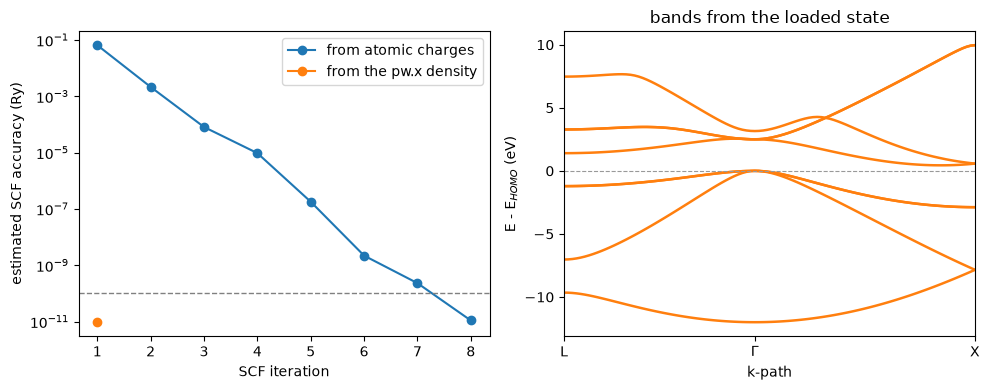

In [3]:
bands = calc.get_bands('L-G-X', nbnd=8)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
for run, label in [(fresh, 'from atomic charges'), (result, 'from the pw.x density')]:
    left.semilogy([h['iteration'] for h in run.history],
                  [h['accuracy'] for h in run.history], 'o-', label=label)
left.axhline(1e-10, color='gray', ls='--', lw=1)
left.set_xlabel('SCF iteration')
left.set_ylabel('estimated SCF accuracy (Ry)')
left.legend()
bands.plot(ax=right, color='C1', lw=1.8)
gamma = np.argmin(np.linalg.norm(np.asarray(bands.kpoints.coords), axis=1))
right.set_xticks(bands.path_length[[0, gamma, -1]], ['L', r'$\Gamma$', 'X'])
right.set_title('bands from the loaded state')
plt.tight_layout()
plt.show()

On the left, the run from atomic charges needs eight iterations to reach the
threshold of $10^{-10}$ Ry, the dashed line, and the run from the `pw.x` density
is below it after the first one. On the right are the bands of silicon from the
loaded state, with the top of the valence band at zero.

This is useful when a ground state is expensive, for example a large cell with a
dense k-mesh. You converge it once with `pw.x`, and here you start every
calculation that needs it from that density. The loaded state is checked against
the `pw.x` energy, and the mapping of the PAW occupations against our own
converged ones, in `tests/unit/test_qe_density.py`. A DFT+U run, a meta-GGA run
and a noncollinear PAW run give an error, because their save folders hold more
than the density and these extra files are not read.